# Construct the forward variance curve

We construct smooth forward variance curves from SPX volatility smiles for the four reference dates: 

2024-12-19, 2025-04-16, 2025-06-20, and 2025-07-02. 

In [ ]:
# Run from either the repository root or R/.
if (!file.exists("fwd_var_curve.R")) setwd("R")
source("fwd_var_curve.R")
source("fukasawa_robust.R")

calibrations <- read.csv("../data/calibration_params.csv",
  colClasses = c(date = "character")
)
CALIB_DATES <- calibrations$date
COLORS <- c("#1e732b", "#6b8203", "#b38a16", "#ed8e6e")

options(repr.plot.width = 8, repr.plot.height = 5.5)


## Robust estimation of the variance contract

By definition, $\xi_t(u)=\mathbb{E}_t[V_u]$. The fair value of the variance contract is
$$M_t(T)=\int_t^T \xi_t(u)\,du,$$
so differentiating with respect to maturity gives $\xi_t(T)=\partial_T M_t(T)$.

We first estimate variance swaps from the volatility smiles, then fit the corresponding total variances.

## Smooth forward curve construction

We apply the smooth curve construction of Filipović and Willems, implemented by Rick Cao and Jim Gatheral, to the variance-swap curve. The resulting forward variance curve is piecewise quadratic.

In practice, input variance swaps are only known up to a bid-offer spread. The `EPS` parameter allows deviations in volatility units when smoothing the curve.

Smoothness alone does not guarantee a positive forward variance curve.

In [ ]:
EPS <- 0.03

u <- seq(0, 0.2, length.out = 101)
curves <- data.frame(u = u)
for (date in CALIB_DATES) {
    spx <- read.csv(paste0("../data/", date, "_spx_vol.csv"))
    swaps <- varSwap.Robust(spx)
    xi <- xi.curve.smooth(
        swaps$expiries, swaps$vs.mid * swaps$expiries,
        eps = EPS
    )$xi.curve
    curves[[date]] <- xi(u)
}


Warning message:
“Forward variance fit did not converge: NEW_X. Returning the fitted curve.”
Warning message:
“Forward variance fit did not converge: NEW_X. Returning the fitted curve.”
Warning message:
“Forward variance fit did not converge: NEW_X. Returning the fitted curve.”
Warning message:
“Forward variance fit did not converge: NEW_X. Returning the fitted curve.”


## Plot the forward variance curves

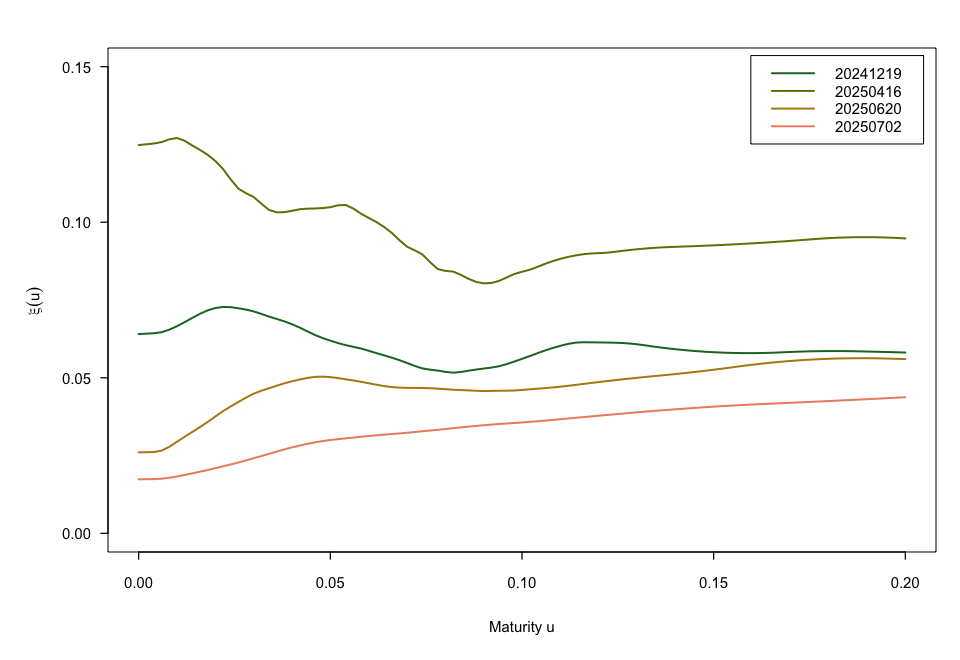

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 5.5)
par(
    bg = "white", mar = c(4.5, 4.5, 2, 1), ps = 9, cex = 1, lwd = 0.8,
    mgp = c(2.5, 0.7, 0), tcl = -0.3, xaxs = "i", yaxs = "i"
)
plot(NA,
    xlim = c(-0.008, 0.208), ylim = c(-0.006, 0.156),
    xlab = "Maturity u", ylab = expression(xi(u)), axes = FALSE
)
axis(1, at = seq(0, 0.2, length.out = 5))
axis(2, at = seq(0, 0.15, length.out = 4), las = 1)
box()
for (i in seq_along(CALIB_DATES)) {
    lines(curves$u, curves[[CALIB_DATES[i]]], col = COLORS[i], lwd = 1.6)
}
legend("topright",
    legend = CALIB_DATES, col = COLORS, lty = 1,
    lwd = 1.6, bg = "white", box.lwd = 0.8, inset = 0.015
)
